# ANÁLISE DO DESENVOLVIMENTO HUMANO E ECONÔMICO GLOBAL

**Grupo:** André Marcus, Gabriel Moreira, Leandro Mendes Thiago Leite

## 1. Título e Introdução

### Tema do projeto

Análise do desenvolvimento humano e econômico global ao longo das décadas, utilizando a base de dados Gapminder e indicadores complementares do Banco Mundial.

### Objetivos da análise

O projeto tem como objetivo compreender a evolução de indicadores socioeconômicos ao longo do tempo, identificando padrões, relações e desigualdades entre países e continentes.

Entre os principais objetivos estão:

- Analisar a evolução da expectativa de vida, do PIB per capita e da população.
- Identificar diferenças no desenvolvimento entre países e continentes.
- Investigar relações entre indicadores econômicos, como inflação, comércio internacional e desemprego.
- Explorar a relação entre desenvolvimento econômico e expectativa de vida.
- Apresentar os resultados por meio de tabelas, gráficos e interpretações.

### Contexto da base de dados

O Gapminder foi desenvolvido a partir do trabalho da Fundação Gapminder, organização sem fins lucrativos criada pelo médico e estatístico sueco Hans Rosling, com o propósito de promover uma compreensão do mundo baseada em dados.

A base reúne informações de mais de 140 países, entre 1952 e 2007, em intervalos de cinco anos, incluindo os seguintes indicadores:

- `lifeExp`: expectativa de vida ao nascer, em anos.
- `gdpPercap`: PIB per capita.
- `pop`: população total.
- `country`: país.
- `continent`: continente.
- `year`: ano de referência.

Como o Gapminder não apresenta todos os indicadores necessários para as análises propostas, também serão utilizadas bases complementares do **Banco Mundial (World Development Indicators)**, com informações sobre inflação, comércio internacional, desemprego e expectativa de vida por sexo.

### Etapas realizadas no notebook

O desenvolvimento do projeto será organizado nas seguintes etapas:

1. **Coleta e integração dos dados:** obtenção da base Gapminder e dos indicadores complementares do Banco Mundial.
2. **Tratamento dos dados:** identificação de valores ausentes e duplicados, limpeza e organização das informações.
3. **Análise exploratória:** investigação dos indicadores por meio de tabelas, estatísticas e gráficos.
4. **Criação de funções reutilizáveis:** desenvolvimento de funções para facilitar a construção e personalização das visualizações.
5. **Interpretação dos resultados:** análise dos padrões identificados e das relações entre os indicadores.
6. **Síntese e conclusão:** apresentação dos principais insights e considerações finais sobre o desenvolvimento humano e econômico global.

### Importação das bibliotecas

In [146]:
# Importar as bibliotecas que serão utilizadas pelo grupo
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



---

## 2. Coleta, Limpeza e Análise Exploratória (AED)

**Objetivo:** preparar os dados, tratando inconsistências e identificando padrões iniciais. Esta seção está organizada por fonte de dados:
- **2.1 Gapminder:** coleta, exploração inicial, limpeza e transformação.
- **2.2 Bases externas (Banco Mundial):** preparação dos indicadores externos e junção com o Gapminder limpo. Cada tema tem a sua subseção (2.2.1 Economia).

### 2.1 Gapminder

#### 2.1.1 Coleta de Dados

O primeiro passo é carregar a base Gapminder e registrar sua origem. Confiram se o arquivo foi disponibilizado junto com o trabalho e anotem a fonte utilizada.

In [147]:
# Informar o caminho correto do arquivo disponibilizado para a atividade
df = pd.read_csv('../data/gapminder_full.csv')

df.head()


,country,year,pop,continent,lifeExp,gdpPercap
0,Afghanistan,1952,8425333.0,Asia,28.801,779.445314
1,Afghanistan,1957,9240934.0,Asia,30.332,820.853030
2,Afghanistan,1962,10267083.0,Asia,31.997,853.100710
3,Afghanistan,1967,11537966.0,Asia,34.020,836.197138
4,Afghanistan,1972,13079460.0,Asia,36.088,739.981106


In [148]:
df.shape

(1736, 6)

#### 2.1.2 Exploração Inicial dos Dados

Antes de tratar os dados, verificar a estrutura do DataFrame e entender os itens em cada colunas.

In [149]:
# Consultar estatísticas descritivas

df.info()

df.describe().round(2)

<class 'pandas.DataFrame'>
RangeIndex: 1736 entries, 0 to 1735
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1736 non-null   str    
 1   year       1736 non-null   int64  
 2   pop        1736 non-null   float64
 3   continent  1736 non-null   str    
 4   lifeExp    1736 non-null   float64
 5   gdpPercap  1736 non-null   float64
dtypes: float64(3), int64(1), str(2)
memory usage: 81.5 KB


,year,pop,lifeExp,gdpPercap
count,1736.00,1.736000e+03,1736.00,1736.00
mean,1979.67,3.156800e+07,59.51,7240.16
std,17.30,1.172888e+08,12.96,9839.87
min,1952.00,6.001100e+04,23.60,241.17
25%,1967.00,2.818694e+06,48.24,1202.06
50%,1982.00,7.150606e+06,60.81,3534.77
75%,1997.00,1.977102e+07,70.94,9380.25
max,2007.00,1.318683e+09,82.60,113523.13


In [150]:
# Verificar os países, continentes e anos presentes na base
print('Quantidade de países:', df['country'].nunique())
print('Continentes:', df['continent'].unique())
print('Anos:', df['year'].unique())

Quantidade de países: 142
Continentes: <StringArray>
['Asia', 'Europe', 'Africa', 'Americas', 'Oceania']
Length: 5, dtype: str
Anos: [1952 1957 1962 1967 1972 1977 1982 1987 1992 1997 2002 2007]


In [151]:
# Quantidade de países em cada continente
df.groupby('continent')['country'].nunique()

continent
Africa      52
Americas    25
Asia        33
Europe      30
Oceania      2
Name: country, dtype: int64

In [152]:
# Quantidade de linhas em cada ano
# (se cada país aparecesse só uma vez, seriam 142 linhas por ano)
df['year'].value_counts().sort_index()

year
1952    143
1957    143
1962    144
1967    144
1972    144
1977    143
1982    143
1987    146
1992    144
1997    147
2002    147
2007    148
Name: count, dtype: int64

**Anotações**
- **Colunas disponíveis:** `country` (país), `year` (ano), `pop` (população), `continent` (continente), `lifeExp` (expectativa de vida) e `gdpPercap` (PIB per capita). São 6 colunas e 1.736 linhas.
- **Período coberto:** de 1952 a 2007, de 5 em 5 anos (12 anos no total).
- **Países e continentes:** 142 países em 5 continentes. A Oceania tem só 2 países, então a média dela deve ser vista com cuidado.
- **O que verificar antes da limpeza:**
  - Cada ano tem entre 143 e 148 linhas, mas o esperado era 142 (um por país). Isso indica que possivelmente existem linhas **duplicadas**.
  - A coluna `pop` está como número decimal (`float64`), mas população é uma contagem de pessoas.

#### 2.1.3 Limpeza de Dados

A atividade solicita excluir os dados ausentes e eliminar registros duplicados. Antes e depois da limpeza, registrem a quantidade de linhas e as decisões tomadas.

In [153]:
# Verificar a quantidade de valores ausentes por coluna | Limpeza abaixo
print('Linhas antes da limpeza:', len(df))
df.isna().sum()

df = df.dropna()
print('Linhas após a limpeza dos valores nulos:', len(df))

Linhas antes da limpeza: 1736
Linhas após a limpeza dos valores nulos: 1736


In [154]:
# Verificar a quantidade de registros duplicados
print(f'Linhas duplicadas: {df.duplicated().sum()}')
print('Abaixo há exmeplos de linhas duplicadas. É possivel verificar essas linhas no arquivo completo do "gapminder_full.csv"')

df[df.duplicated()].head(10)

Linhas duplicadas: 32
Abaixo há exmeplos de linhas duplicadas. É possivel verificar essas linhas no arquivo completo do "gapminder_full.csv"


,country,year,pop,continent,lifeExp,gdpPercap
72,Afghanistan,1997,2.222742e+07,Asia,41.763,635.341351
145,Bolivia,1987,6.156369e+06,Americas,57.251,2753.691490
146,Bolivia,1992,6.893451e+06,Americas,59.957,2961.699694
147,Bolivia,1997,7.693188e+06,Americas,62.050,3326.143191
148,Bolivia,2002,8.445134e+06,Americas,63.883,3413.262690
149,Bolivia,2007,9.119152e+06,Americas,65.554,3822.137084
161,Belgium,2007,1.039223e+07,Europe,79.441,33692.605080
207,Burkina Faso,1987,7.586551e+06,Africa,49.557,912.063142
232,Cambodia,1987,8.371791e+06,Asia,53.914,683.895573
345,China,1997,1.230075e+09,Asia,70.426,2289.234136


In [155]:
# Eliminar registros duplicados e corrigindo os indices conforme ensinado
print('Linhas antes da limpeza:', len(df))
df = df.drop_duplicates()

print('Linhas após a limpeza dos duplicados:', len(df))
df = df.reset_index(drop=True)

Linhas antes da limpeza: 1736
Linhas após a limpeza dos duplicados: 1704


In [156]:
# Conferir a base após a limpeza

print('Linhas depois da limpeza:', len(df))
print('Duplicados restantes:', df.duplicated().sum())
print('Ausentes restantes:', df.isna().sum().sum())
df['year'].value_counts().sort_index()

Linhas depois da limpeza: 1704
Duplicados restantes: 0
Ausentes restantes: 0


year
1952    142
1957    142
1962    142
1967    142
1972    142
1977    142
1982    142
1987    142
1992    142
1997    142
2002    142
2007    142
Name: count, dtype: int64

**Decisões de tratamento**
- **Valores ausentes:** nenhum foi encontrado. Mantendo a mesma quantidade de linhas antes e após a limpeza.
- **Duplicados:** foram encontradas e removidas (32 linhas duplicadas).
- **Registros que restaram:** de 1.736 para 1.704 linhas, que é 142 países × 12 anos. Da forma que era esperado na etapa 2

#### 2.1.4 Transformação e Preparação dos Dados

Avaliando se é necessário ajustar tipos de dados, nomes de colunas ou outras tarefas para facilitar as análises.

In [157]:
# Vê quais dados poderm ser alterados e converte a população para inteiros
df.info()

df['pop'] = df['pop'].round().astype('int64')
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   str    
 1   year       1704 non-null   int64  
 2   pop        1704 non-null   float64
 3   continent  1704 non-null   str    
 4   lifeExp    1704 non-null   float64
 5   gdpPercap  1704 non-null   float64
dtypes: float64(3), int64(1), str(2)
memory usage: 80.0 KB


,country,year,pop,continent,lifeExp,gdpPercap
0,Afghanistan,1952,8425333,Asia,28.801,779.445314
1,Afghanistan,1957,9240934,Asia,30.332,820.853030
2,Afghanistan,1962,10267083,Asia,31.997,853.100710
3,Afghanistan,1967,11537966,Asia,34.020,836.197138
4,Afghanistan,1972,13079460,Asia,36.088,739.981106


In [158]:
# Cria uma base de dados limpa que vai ser utilizada para fazer as análises
df.to_csv('../data/gapminder_limpo.csv', index=False)

### 2.2 Bases Externas (Banco Mundial)

Para responder perguntas sobre inflação, comércio, desemprego e diferença de expectativa de vida entre homens e mulheres, será utilizado bases do "Banco Mundial (World Development Indicators)", baixadas em https://data.worldbank.org.

Aqui é feito a preparação dos dados para comn=binar com o gapMinder que limpamos:
1. Ler os arquivos baixados.
2. Arrumar o formato da tabela (uma linha por país e ano).
3. Conferir se os nomes dos países batem com os do Gapminder.
4. Juntar com o `df` (Gapminder limpo) usando `country` e `year`.
5. Ver quantos dados ausentes sobraram.

#### 2.2.1 Economia (André)

Bases externas que será usada para analise de perguntas relacionadas a economia:

| Nome da coluna | Indicador do Banco Mundial | Unidade |
|---|---|---|
| `inflacao` | Inflação, preços ao consumidor | % ao ano |
| `comercio` | Comércio (exportações + importações) | % do PIB |
| `cresc_pib` | Crescimento do PIB per capita | % ao ano |
| `desemprego` | Desemprego total (estimativa modelada da OIT) | % da força de trabalho |
| `vida_f` | Expectativa de vida ao nascer, mulheres | anos |
| `vida_m` | Expectativa de vida ao nascer, homens | anos |

In [159]:
# Organizando os caminhos para os arquivos, já que serão usados em algumas analises.

pasta = '../data/Economia/'

arquivos_economia = {
    'inflacao':   'API_FP.CPI.TOTL.ZG_DS2_en_csv_v2_1323.csv',
    'comercio':   'API_NE.TRD.GNFS.ZS_DS2_en_csv_v2_1202.csv',
    'cresc_pib':  'API_NY.GDP.PCAP.KD.ZG_DS2_en_csv_v2_6324.csv',
    'desemprego': 'API_SL.UEM.TOTL.ZS_DS2_en_csv_v2_1675.csv',
    'vida_f':     'API_SP.DYN.LE00.FE.IN_DS2_en_csv_v2_7315.csv',
    'vida_m':     'API_SP.DYN.LE00.MA.IN_DS2_en_csv_v2_3426.csv',
}

***Padronizando e lendo os arquivos***

O Gapminder e as fontes de dados vindo do WorldBank possuem uma estrutura diferente, então vai ser criado uma função simples, para não repetir o mesmo código seis vezes.
O 'melt' é usado para padronizar as colunas de anos em linhas, para facilitar a leitura, já os arquivos são diferentes

In [160]:
def ler_indicador(arquivo, nome_coluna):

    tabela = pd.read_csv(pasta + arquivo, skiprows=4)

    # Colunas que não iremos usar
    tabela = tabela.drop(columns=['Country Code', 'Indicator Name', 'Indicator Code', 'Unnamed: 70'],
                         errors='ignore')


    tabela = tabela.melt(id_vars='Country Name', var_name='year', value_name=nome_coluna)


    tabela = tabela.rename(columns={'Country Name': 'country'})
    tabela['year'] = tabela['year'].astype(int)

    return tabela

***Junta os indicadores***
Juntando os indicadores para estarem em uma tabela

In [161]:
# Começa vazia e vai juntando um indicador por vez
wb_economia = None

for nome, arquivo in arquivos_economia.items():
    tabela = ler_indicador(arquivo, nome)

    if wb_economia is None:
        wb_economia = tabela
    else:
        wb_economia = wb_economia.merge(tabela, on=['country', 'year'], how='outer')

print('Linhas e colunas:', wb_economia.shape)
wb_economia.head()

Linhas e colunas: (17556, 8)


,country,year,inflacao,comercio,cresc_pib,desemprego,vida_f,vida_m
0,Afghanistan,1960,NaN,NaN,NaN,NaN,33.549,32.136
1,Afghanistan,1961,NaN,NaN,NaN,NaN,34.043,32.626
2,Afghanistan,1962,NaN,NaN,NaN,NaN,34.502,33.098
3,Afghanistan,1963,NaN,NaN,NaN,NaN,34.945,33.543
4,Afghanistan,1964,NaN,NaN,NaN,NaN,35.428,34.004


Como tem uma descrepancia no nome dos paises entre essas duas fontes, vamos verificar e modificar as que conseguimos

In [162]:
# Países do Gapminder que não aparecem no WorldBank
paises_gapminder = set(df['country'].unique())
paises_wb = set(wb_economia['country'].unique())

nao_encontrados = sorted(paises_gapminder - paises_wb)
print('Quantidade:', len(nao_encontrados))
print(nao_encontrados)

Quantidade: 19
['Congo Dem. Rep.', 'Congo Rep.', 'Czech Republic', 'Egypt', 'Gambia', 'Hong Kong China', 'Iran', 'Korea Dem. Rep.', 'Korea Rep.', 'Puerto Rico', 'Reunion', 'Somalia', 'Swaziland', 'Syria', 'Taiwan', 'Turkey', 'Venezuela', 'Vietnam', 'Yemen Rep.']


In [163]:
# Corrigindo o nome de paises do World Bank para o nome no Gapminder
correcao_nomes = {
    'Congo, Dem. Rep.': 'Congo Dem. Rep.',
    'Congo, Rep.': 'Congo Rep.',
    'Czechia': 'Czech Republic',
    'Egypt, Arab Rep.': 'Egypt',
    'Gambia, The': 'Gambia',
    'Hong Kong SAR, China': 'Hong Kong China',
    'Iran, Islamic Rep.': 'Iran',
    "Korea, Dem. People's Rep.": 'Korea Dem. Rep.',
    'Korea, Rep.': 'Korea Rep.',
    'Puerto Rico (US)': 'Puerto Rico',
    'Somalia, Fed. Rep.': 'Somalia',
    'Eswatini': 'Swaziland',
    'Syrian Arab Republic': 'Syria',
    'Turkiye': 'Turkey',
    'Venezuela, RB': 'Venezuela',
    'Viet Nam': 'Vietnam',
    'Yemen, Rep.': 'Yemen Rep.',
}

wb_economia['country'] = wb_economia['country'].replace(correcao_nomes)

# Conferindo de novo quais países continuam sem correspondência
paises_wb = set(wb_economia['country'].unique())
print('Ainda não encontrados:', sorted(paises_gapminder - paises_wb))

Ainda não encontrados: ['Reunion', 'Taiwan']


In [164]:
# Junta o Gapminder limpo com os indicadores do WB depois remove ausentes
df_economia = df.merge(wb_economia, on=['country', 'year'], how='left')

print('Linhas antes:', len(df))
print('Linhas depois:', len(df_economia))
print('Duplicados em país/ano:', df_economia.duplicated(['country', 'year']).sum())

df_economia.head()



Linhas antes: 1704
Linhas depois: 1704
Duplicados em país/ano: 0


,country,year,pop,continent,lifeExp,gdpPercap,inflacao,comercio,cresc_pib,desemprego,vida_f,vida_m
0,Afghanistan,1952,8425333,Asia,28.801,779.445314,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,1957,9240934,Asia,30.332,820.853030,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,1962,10267083,Asia,31.997,853.100710,NaN,NaN,NaN,NaN,34.502,33.098
3,Afghanistan,1967,11537966,Asia,34.020,836.197138,NaN,NaN,NaN,NaN,36.851,35.324
4,Afghanistan,1972,13079460,Asia,36.088,739.981106,NaN,NaN,NaN,NaN,39.255,37.681


In [165]:
df_economia.isna().sum()
colunas_wb = list(arquivos_economia.keys())

df_economia.groupby('year')[colunas_wb].count()

,inflacao,comercio,cresc_pib,desemprego,vida_f,vida_m
year,,,,,,
1952,0,0,0,0,0,0
1957,0,0,0,0,0,0
1962,62,59,100,0,139,139
1967,78,70,104,0,139,139
1972,84,92,112,0,139,139
1977,88,95,114,0,139,139
1982,93,101,122,0,139,139
1987,103,103,124,0,139,139
1992,111,114,133,140,140,140


---

## 3. Funções de Visualização e Análise Gráfica

**Objetivo:** criar funções reutilizáveis para gerar gráficos e apoiar as análises, evitando repetir o mesmo código várias vezes.


| Função | Tipo de gráfico | Quando usar |
|---|---|---|
| `grafico_linha` | Linhas | Mostrar a evolução no tempo; com `hue`, compara grupos (ex.: continentes) |
| `grafico_barras` | Barras | Comparar categorias e fazer rankings (média, soma ou mediana por grupo) |
| `grafico_dispersao` | Dispersão | Ver a relação entre duas variáveis; aceita cor por grupo, tamanho por coluna, escala logarítmica e linha de tendência |
| `grafico_histograma` | Histograma | Ver a distribuição de uma variável (onde os valores se concentram) |
| `grafico_boxplot` | Boxplot | Comparar a distribuição entre grupos e identificar valores extremos |
| `grafico_correlacao` | Mapa de calor | Ver a correlação entre várias colunas de uma vez (de -1 a 1) |


In [166]:
# Função para criar um gráfico de linhas
def grafico_linha(dados, x, y, titulo, xlabel, ylabel, tamanho_img=(8, 5)):
    dados_grafico = dados[[x, y]].dropna().sort_values(x)

    plt.figure(tamanho_img=tamanho_img)
    plt.plot(dados_grafico[x], dados_grafico[y], marker='o')
    plt.title(titulo)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.xticks(rotation=45)
    plt.grid()
    plt.tight_layout()
    plt.show()

In [167]:
# Função para criar um gráfico de barras
def grafico_barras(dados, x, y, titulo, xlabel, ylabel, horizontal=False, tamanho_img=(8, 5)):
    dados_grafico = dados[[x, y]].dropna()

    plt.figure(tamanho_img=tamanho_img)

    if horizontal:
        plt.barh(dados_grafico[x], dados_grafico[y])
    else:
        plt.bar(dados_grafico[x], dados_grafico[y])
        plt.xticks(rotation=45)

    plt.title(titulo)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.show()

In [168]:
# Função para criar um gráfico de dispersão
def grafico_dispersao(dados, x, y, titulo, xlabel, ylabel, tamanho_img=(8, 5), hue=None):
    colunas = [x, y]
    if hue != None:
        colunas.append(hue)

    dados_grafico = dados[colunas].dropna()

    plt.figure(tamanho_img=tamanho_img)

    if hue == None:
        plt.scatter(dados_grafico[x], dados_grafico[y])
    else:
        for grupo in dados_grafico[hue].unique():
            dados_grupo = dados_grafico[dados_grafico[hue] == grupo]
            plt.scatter(
                dados_grupo[x],
                dados_grupo[y],
                label=grupo
            )

        plt.legend(title='Continente' if hue == 'continent' else hue)

    plt.title(titulo)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.grid()
    plt.tight_layout()
    plt.show()

In [169]:
# Função para mostrar os 10 países que mais se destacam em um gráfico de dispersão
def tabela_destaques_dispersao(dados, x, y, coluna_destaque=None, titulo='10 países em destaque', quantidade=10):
    if coluna_destaque == None:
        coluna_destaque = y

    colunas = ['country']
    if 'continent' in dados.columns:
        colunas.append('continent')
    colunas.extend([x, y])
    colunas = list(dict.fromkeys(colunas))

    tabela = dados[colunas].dropna(subset=[x, y, coluna_destaque])
    tabela = tabela.sort_values(coluna_destaque, ascending=False).head(quantidade)

    print(titulo)
    return tabela.round(2).reset_index(drop=True)

In [170]:
# Função para criar um histograma
def grafico_histograma(dados, coluna, titulo, xlabel, bins=15, tamanho_img=(8, 5)):
    valores = dados[coluna].dropna()

    plt.figure(tamanho_img=tamanho_img)
    plt.hist(valores, bins=bins, edgecolor='black')
    plt.title(titulo)
    plt.xlabel(xlabel)
    plt.ylabel('Quantidade de registros')
    plt.tight_layout()
    plt.show()

In [171]:
# Função para criar um boxplot
def grafico_boxplot(dados, coluna, titulo, ylabel, tamanho_img=(8, 5)):
    valores = dados[coluna].dropna()

    plt.figure(tamanho_img=tamanho_img)
    plt.boxplot(valores)
    plt.title(titulo)
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.show()

In [172]:
def grafico_correlacao(dados, colunas, ano=None, metodo='pearson', titulo='', tamanho_img=(6, 5)):
    d = dados if ano is None else dados[dados['year'] == ano]
    d = d[colunas].dropna()

    plt.figure(tamanho_img=tamanho_img)
    sns.heatmap(d.corr(method=metodo), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
    plt.title(titulo, fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

---

## 4. Interpretação das Visualizações

Escolham pelo menos **15 perguntas** para investigar. Para cada análise, incluam código, tabela ou gráfico e uma interpretação escrita pelo grupo (usando, quando fizer sentido, as funções da seção 3). As perguntas abaixo são sugestões; vocês podem adaptar ou substituir por outras relacionadas ao objetivo do trabalho.

Na interpretação de cada análise, expliquem:
- O que o gráfico ou a tabela mostra e por que esse tipo de visualização foi escolhido?
- Que comparação ou tendência chamou atenção?
- A pergunta inicial foi respondida?
- Existe alguma limitação que precisa ser considerada?


#### Análise 1 — Inflação e crescimento do PIB per capita (Economia – André)
**Pergunta:** Países com maiores taxas de inflação apresentam diferenças no crescimento do PIB per capita em comparação com países com inflação mais estável?

**Visualização escolhida:** Gráficos de barras. Primeiro calculamos a média de inflação e de crescimento do PIB per capita de cada país (de 1962 a 2007, só países com pelo menos 5 anos de dados). Depois comparamos os 10 países de maior inflação com os 10 de menor inflação, usando a mediana do crescimento, porque poucos países com valores extremos distorcem a média.



In [173]:
inf = df_economia.dropna(subset=['inflacao', 'cresc_pib'])
por_pais = inf.groupby('country')[['inflacao', 'cresc_pib']].mean()

anos = inf.groupby('country')['year'].count()
por_pais['anos'] = anos
por_pais = por_pais[por_pais['anos'] >= 5]

# Seleciona os 10 países com maior e menor inflação média
maiores = por_pais.sort_values('inflacao', ascending=False).head(10).round(2)
menores = por_pais.sort_values('inflacao').head(10).round(2)

print('países analisados:', len(por_pais), ' países')
print('10 países com maior inflação média:')
print(maiores)
print()
print('10 países com menor inflação média:')
print(menores)

países analisados: 99  países
10 países com maior inflação média:
                 inflacao  cresc_pib  anos
country                                   
Congo Dem. Rep.    512.58      -3.04     9
Bulgaria           233.32       0.33     5
Brazil             216.64       1.09     6
Zambia              54.01       0.56     5
Uruguay             42.78       0.28    10
Turkey              33.67       3.88    10
Indonesia           30.58       2.67    10
Peru                29.60       2.50    10
Sudan               29.13       3.75    10
Chile               28.50       2.66     8

10 países com menor inflação média:
                          inflacao  cresc_pib  anos
country                                            
Chad                         -1.46       1.06     5
Equatorial Guinea            -0.81      38.57     5
Central African Republic      1.70      -0.44     6
Singapore                     1.94       5.87    10
Saudi Arabia                  2.41      -2.23     9
Panama           

In [174]:
grafico_maiores = maiores.reset_index().sort_values('inflacao')


grafico_barras(
    dados=grafico_maiores,
    x='country',
    y='inflacao',
    titulo='10 países com maior inflação média (1962-2007)',
    xlabel='Inflação média (% ao ano)',
    ylabel='País',
    horizontal=True,
    figsize=(10, 6)
)

TypeError: grafico_barras() got an unexpected keyword argument 'figsize'

            grupo  cresc_pib
0  Maior inflação       1.80
1  Menor inflação       2.48


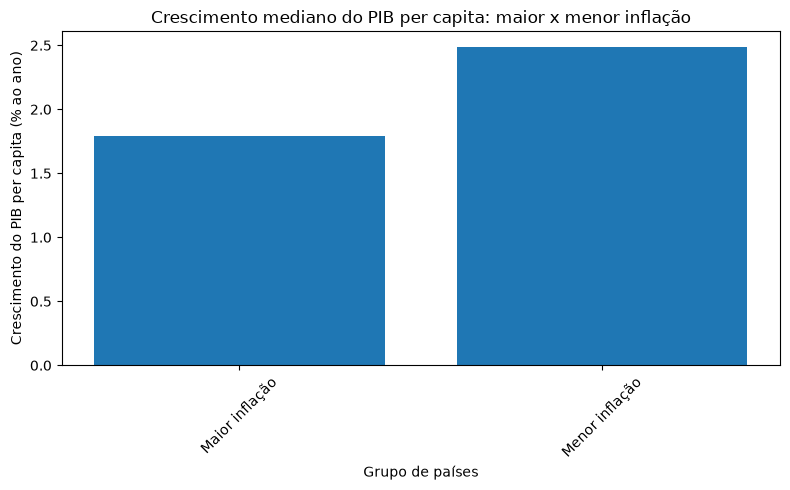

In [ ]:
# Identificar o grupo de cada país e os junta
maiores['grupo'] = 'Maior inflação'
menores['grupo'] = 'Menor inflação'

grupos = pd.concat([maiores, menores])

# Calcula a mediana do crescimento do PIB dos grupos
resultado = grupos.groupby('grupo')['cresc_pib'].median().reset_index()
print(resultado.round(2))

# Gráfico 2: compara o crescimento do PIB entre os grupos
grafico_barras(
    dados=resultado,
    x='grupo',
    y='cresc_pib',
    titulo='Crescimento mediano do PIB per capita: maior x menor inflação',
    xlabel='Grupo de países',
    ylabel='Crescimento do PIB per capita (% ao ano)'
)

**Interpretação do grupo:**

Entre os 10 países com maior inflação média, o crescimento mediano do PIB per capita foi de 1,80% ao ano ao longo do periodo analisado (1962 - 2007). Entre os 10 com menor inflação, foi de 2,48%. O grupo de menor inflação apresentou crescimento um pouco maior, mas valores extremos e a quantidade diferente de anos disponíveis também influenciam o resultado, porém com base nos dados disponiveis esse aumento do PIB entre paises com maior e menor inflação estão próximos da faixa visualizada.

#### Análise 2 — Comércio internacional e PIB per capita (Economia – André)
**Pergunta:** Países com maior participação do comércio internacional em suas economias apresentam maior PIB per capita?

**Visualização escolhida:** Gráfico de dispersão entre comércio (% do PIB) e PIB per capita em 2007, com cor por continente. O PIB per capita está em escala logarítmica, porque poucos países têm valores muito altos. Foi usado um único ano (2007) para comparar os países na mesma época.


In [ ]:
comercio_df = df_economia.copy()
comercio_df.loc[comercio_df['comercio'] == 0, 'comercio'] = np.nan

# Seleciona os dados de 2007
dados_comercio = comercio_df[comercio_df['year'] == 2007].copy()
dados_comercio = dados_comercio.dropna(subset=['comercio', 'gdpPercap'])

print('Países utilizados:', len(dados_comercio))

correlacao = dados_comercio['comercio'].corr(dados_comercio['gdpPercap'])
print('Correlação entre comércio e PIB per capita:', round(correlacao, 2))

Países utilizados: 125
Correlação entre comércio e PIB per capita: 0.35


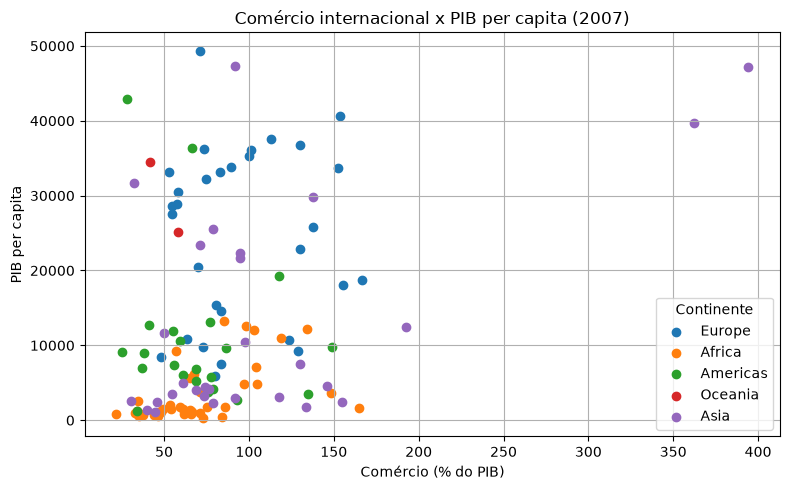

In [ ]:
grafico_dispersao(
    dados=dados_comercio,
    x='comercio',
    y='gdpPercap',
    titulo='Comércio internacional x PIB per capita (2007)',
    xlabel='Comércio (% do PIB)',
    ylabel='PIB per capita',
    hue='continent'
)

In [ ]:
# Tabela: 10 países com maior PIB per capita no gráfico
tabela_destaques_dispersao(
    dados=dados_comercio,
    x='comercio',
    y='gdpPercap',
    coluna_destaque='gdpPercap',
    titulo='10 países com maior PIB per capita (2007)'
)

10 países com maior PIB per capita (2007)


,country,continent,comercio,gdpPercap
0,Norway,Europe,71.17,49357.19
1,Kuwait,Asia,91.73,47306.99
2,Singapore,Asia,394.29,47143.18
3,United States,Americas,28.01,42951.65
4,Ireland,Europe,153.40,40676.00
5,Hong Kong China,Asia,362.15,39724.98
6,Switzerland,Europe,112.71,37506.42
7,Netherlands,Europe,129.80,36797.93
8,Canada,Americas,66.28,36319.24
9,Iceland,Europe,73.62,36180.79


**Interpretação do grupo:**
Foram analisados 125 países no periodo do ano de 2007. A correlação entre comércio internacional e PIB per capita foi de 0,35, indicando uma relação positiva moderada: países com maior participação do comércio tendem a apresentar PIB per capita mais alto. Porém, há diferenças entre países e continentes, portanto o comércio, sozinho, não explica o nível de renda.

#### Análise 3 — Desemprego, crescimento e nível de renda (Economia – André)
**Pergunta:** Países com maiores taxas de desemprego apresentam menor crescimento do PIB per capita ou diferenças nos níveis de renda entre países?

**Visualização escolhida:** Dois gráficos de dispersão com os dados de 2007: desemprego x crescimento do PIB per capita, e desemprego x PIB per capita (em escala logarítmica). A base de desemprego só tem os anos de 1992, 1997, 2002 e 2007, então conferimos a correlação em cada um deles.


In [ ]:
# Selecionar os dados de 2007
dados_desemprego = df_economia[df_economia['year'] == 2007].copy()
dados_desemprego = dados_desemprego.dropna(
    subset=['desemprego', 'cresc_pib', 'gdpPercap']
)

print('Países utilizados:', len(dados_desemprego))

# Calcula as relações entre os indicadores de desemprego, crescimento do PIB e PIB per capita
correlacao_crescimento = dados_desemprego['desemprego'].corr(dados_desemprego['cresc_pib'])
correlacao_renda = dados_desemprego['desemprego'].corr(dados_desemprego['gdpPercap'])

print('Correlação entre desemprego e crescimento do PIB:', round(correlacao_crescimento, 2))
print('Correlação entre desemprego e PIB per capita:', round(correlacao_renda, 2))

Países utilizados: 138
Correlação entre desemprego e crescimento do PIB: 0.04
Correlação entre desemprego e PIB per capita: -0.15


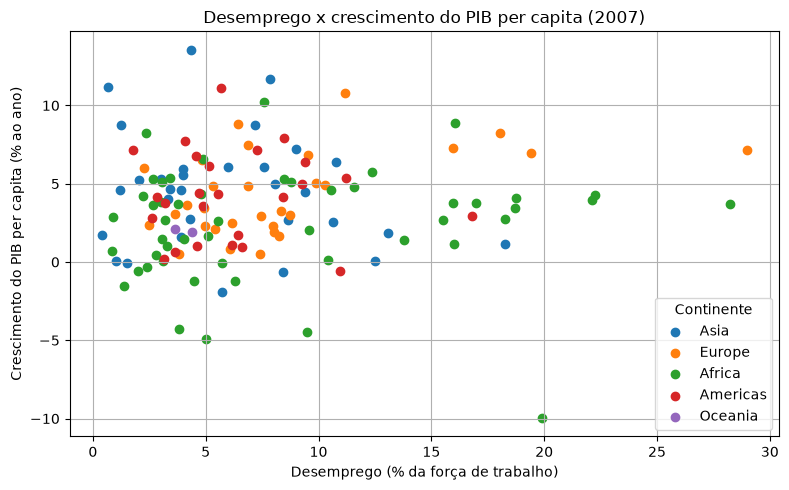

In [ ]:
# desemprego e crescimento do PIB per capita
grafico_dispersao(
    dados=dados_desemprego,
    x='desemprego',
    y='cresc_pib',
    titulo='Desemprego x crescimento do PIB per capita (2007)',
    xlabel='Desemprego (% da força de trabalho)',
    ylabel='Crescimento do PIB per capita (% ao ano)',
    hue='continent'
)

In [ ]:
# 10 países com maiores taxas de desemprego
tabela_destaques_dispersao(
    dados=dados_desemprego,
    x='desemprego',
    y='cresc_pib',
    coluna_destaque='desemprego',
    titulo='10 países com maior taxa de desemprego (2007)'
)

10 países com maior taxa de desemprego (2007)


,country,continent,desemprego,cresc_pib
0,Bosnia and Herzegovina,Europe,28.98,7.17
1,Swaziland,Africa,28.24,3.72
2,South Africa,Africa,22.26,4.25
3,Namibia,Africa,22.12,3.98
4,Congo Rep.,Africa,19.91,-9.97
5,Montenegro,Europe,19.40,6.99
6,Libya,Africa,18.77,4.07
7,Somalia,Africa,18.69,3.42
8,West Bank and Gaza,Asia,18.28,1.17
9,Gabon,Africa,18.26,2.75


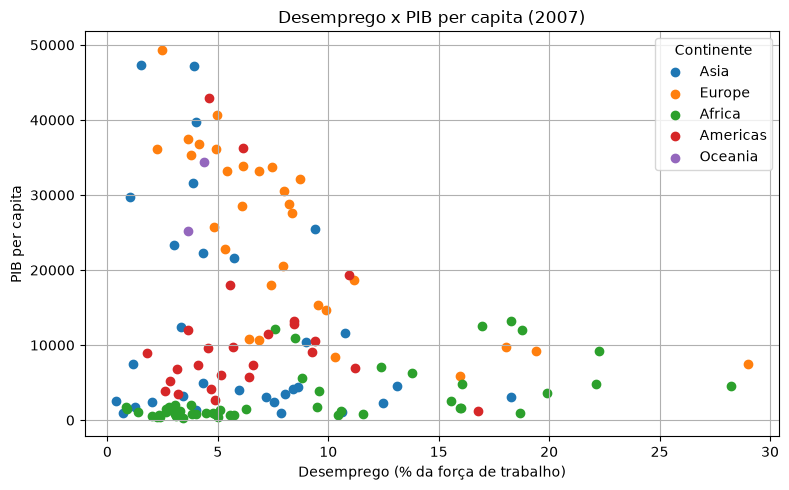

In [ ]:
# desemprego e PIB per capita
grafico_dispersao(
    dados=dados_desemprego,
    x='desemprego',
    y='gdpPercap',
    titulo='Desemprego x PIB per capita (2007)',
    xlabel='Desemprego (% da força de trabalho)',
    ylabel='PIB per capita',
    hue='continent'
)

In [ ]:
# os mesmos países com maior desemprego e seus níveis de renda
# Assim é possível comparar desemprego e PIB per capita.
tabela_destaques_dispersao(
    dados=dados_desemprego,
    x='desemprego',
    y='gdpPercap',
    coluna_destaque='desemprego',
    titulo='PIB per capita dos 10 países com maior desemprego (2007)'
)

PIB per capita dos 10 países com maior desemprego (2007)


,country,continent,desemprego,gdpPercap
0,Bosnia and Herzegovina,Europe,28.98,7446.30
1,Swaziland,Africa,28.24,4513.48
2,South Africa,Africa,22.26,9269.66
3,Namibia,Africa,22.12,4811.06
4,Congo Rep.,Africa,19.91,3632.56
5,Montenegro,Europe,19.40,9253.90
6,Libya,Africa,18.77,12057.50
7,Somalia,Africa,18.69,926.14
8,West Bank and Gaza,Asia,18.28,3025.35
9,Gabon,Africa,18.26,13206.48


**Interpretação do grupo:**

Foram analisados 138 países em 2007. A correlação entre desemprego e crescimento do PIB per capita foi de 0,04, o que é muito baixo, quase nada. Já entre desemprego e PIB per capita foi de -0,15, uma relação negativa fraca. Assim, os dados não mostram uma associação linear relevante entre desemprego e crescimento, nem uma relação forte com o nível de renda.

#### Análise 4 — Diferença de expectativa de vida entre mulheres e homens e PIB per capita (Economia – André)
**Pergunta:** A diferença de expectativa de vida entre homens e mulheres aumenta ou diminui conforme o PIB per capita cresce?

**Visualização escolhida:** Um gráfico de dispersão compara o PIB per capita médio com a diferença média de expectativa de vida de cada país. Também mostramos a evolução média da expectativa de vida feminina e masculina nos anos disponíveis. Foram considerados apenas os anos em que Gapminder e os dois indicadores do Banco Mundial possuem dados, mantendo países com informações em todos esses anos para a comparação principal.

In [ ]:
dados_vida = df_economia.dropna(subset=['gdpPercap', 'vida_f', 'vida_m']).copy()
dados_vida = dados_vida[dados_vida['gdpPercap'] > 0]

# Diferença positiva significa que a expectativa de vida feminina é maior.
dados_vida['dif_vida'] = dados_vida['vida_f'] - dados_vida['vida_m']

anos_disponiveis = sorted(dados_vida['year'].unique())
print('Anos utilizados na análise:', anos_disponiveis)
print('Total de anos:', len(anos_disponiveis))
print('Quantidade de países com dados em cada ano:')
display(
    dados_vida.groupby('year')['country']
    .nunique()
    .reset_index(name='quantidade_paises')
)

# Calcula a média dos indicadores para cada país ao longo dos anos disponíveis.
resumo_vida = (
    dados_vida.groupby(['country', 'continent'])
    .agg(
        pib_medio=('gdpPercap', 'mean'),
        vida_f_media=('vida_f', 'mean'),
        vida_m_media=('vida_m', 'mean'),
        dif_vida_media=('dif_vida', 'mean'),
        anos_analisados=('year', 'nunique')
    )
    .reset_index()
)

resumo_vida = resumo_vida[
    resumo_vida['anos_analisados'] == len(anos_disponiveis)
].copy()

correlacao = resumo_vida['pib_medio'].corr(
    resumo_vida['dif_vida_media'],
    method='spearman'
)

print('Países com dados completos em todos os anos:', resumo_vida['country'].nunique())
print('Correlação de Spearman:', round(correlacao, 2))


Anos utilizados na análise: [np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]
Total de anos: 10
Quantidade de países com dados em cada ano:


,year,quantidade_paises
0,1962,139
1,1967,139
2,1972,139
3,1977,139
4,1982,139
5,1987,139
6,1992,140
7,1997,140
8,2002,140
9,2007,140


Países com dados completos em todos os anos: 139
Correlação de Spearman: 0.59


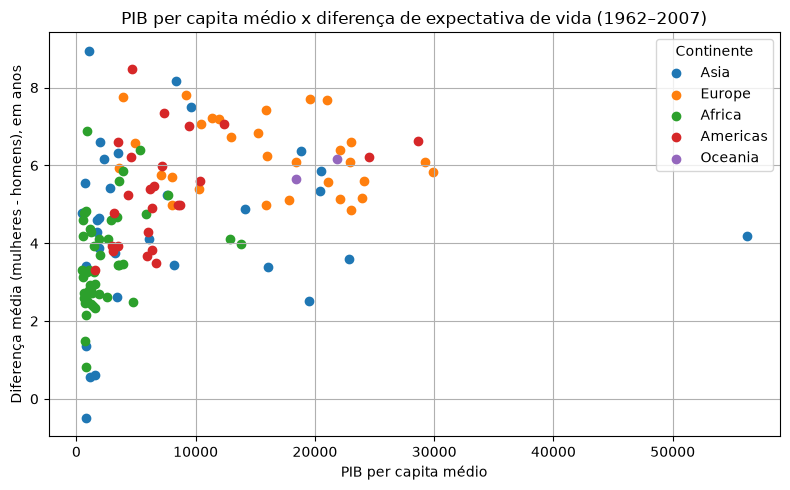

In [ ]:
# Gráfico: PIB per capita médio x diferença média de expectativa de vida
# Cada ponto representa um país; as cores identificam os continentes.
grafico_dispersao(
    dados=resumo_vida,
    x='pib_medio',
    y='dif_vida_media',
    titulo='PIB per capita médio x diferença de expectativa de vida (1962–2007)',
    xlabel='PIB per capita médio',
    ylabel='Diferença média (mulheres - homens), em anos',
    hue='continent',
)




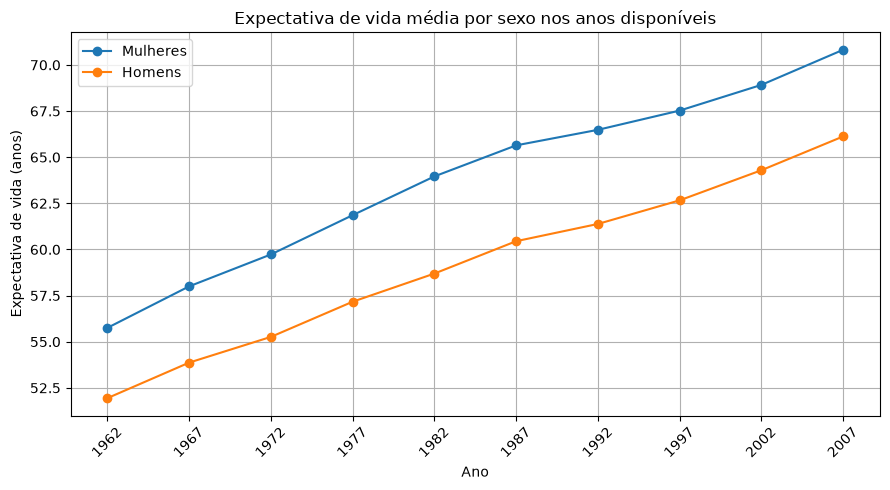

Diferença média entre mulheres e homens por ano:


,year,dif_vida
0,1962,3.81
1,1967,4.13
2,1972,4.47
3,1977,4.69
4,1982,5.26
5,1987,5.19
6,1992,5.10
7,1997,4.86
8,2002,4.62
9,2007,4.70


In [ ]:
# Compara a expectativa de vida média de mulheres e homens em cada ano disponível.
vida_por_ano = (
    dados_vida.groupby('year')[['vida_f', 'vida_m', 'dif_vida']]
    .mean()
    .reset_index()
)

plt.figure(figsize=(9, 5))
plt.plot(vida_por_ano['year'], vida_por_ano['vida_f'], marker='o', label='Mulheres')
plt.plot(vida_por_ano['year'], vida_por_ano['vida_m'], marker='o', label='Homens')
plt.title('Expectativa de vida média por sexo nos anos analisados')
plt.xlabel('Ano')
plt.ylabel('Expectativa de vida (anos)')
plt.xticks(vida_por_ano['year'], rotation=45)
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

print('Diferença média entre mulheres e homens por ano:')
display(vida_por_ano[['year', 'dif_vida']].round(2))


In [ ]:
print('Diferença média de expectativa de vida (mulheres − homens), em anos')
tabela_destaques_dispersao(
    dados=resumo_vida,
    x='pib_medio',
    y='dif_vida_media',
    coluna_destaque='dif_vida_media',
    titulo='10 países com maior diferença média de expectativa de vida (período analisado)'
)


Diferença média de expectativa de vida (mulheres − homens), em anos
10 países com maior diferença média de expectativa de vida (período analisado)


,country,continent,pib_medio,dif_vida_media
0,Vietnam,Asia,1093.12,8.95
1,El Salvador,Americas,4671.23,8.47
2,Iraq,Asia,8338.26,8.18
3,Poland,Europe,9223.51,7.81
4,Bosnia and Herzegovina,Europe,3948.98,7.77
5,Finland,Europe,19571.47,7.72
6,France,Europe,21031.02,7.69
7,Korea Rep.,Asia,9608.96,7.50
8,Slovenia,Europe,15881.77,7.42
9,Uruguay,Americas,7333.41,7.34


**Interpretação do grupo:**

Foram analisados 139 países com dados completos nos 10 anos disponíveis (1962 a 2007) e comparado com a fonte do World Bank (Banco Mundial). A correlação de Spearman foi de 0,59, indicando uma associação positiva moderada: países com maior PIB per capita médio tendem a apresentar uma diferença maior de expectativa de vida a favor das mulheres. A relação é uma associação e pode ser um dos indicadores que demonstra que o aumento do PIB cause essa diferença.

#### Análise 5 — PIB por continente
**Pergunta:** Como o PIB per capita se distribui entre os continentes em um ano escolhido?

**Visualização possível:** Gráfico de barras ou boxplot.

**Etapa atual: 🟩 ANÁLISE**

Registrem abaixo o código necessário para investigar a pergunta.

In [ ]:
# Desenvolver a análise do grupo

**Interpretação do grupo:**

[Escrever aqui o que os resultados mostram, citando evidências do gráfico ou da tabela.]

#### Análise 6 — Expectativa de vida e PIB
**Pergunta:** Existe uma relação visual entre PIB per capita e expectativa de vida?

**Visualização possível:** Gráfico de dispersão.

**Etapa atual: 🟩 ANÁLISE**

Registrem abaixo o código necessário para investigar a pergunta.

In [ ]:
# Desenvolver a análise do grupo

**Interpretação do grupo:**

[Escrever aqui o que os resultados mostram, citando evidências do gráfico ou da tabela.]

#### Análise 7 — Países com maior expectativa de vida
**Pergunta:** Quais países apresentam os maiores valores de expectativa de vida em um ano escolhido?

**Visualização possível:** Tabela de ranking ou gráfico de barras.

**Etapa atual: 🟩 ANÁLISE**

Registrem abaixo o código necessário para investigar a pergunta.

In [ ]:
# Desenvolver a análise do grupo

**Interpretação do grupo:**

[Escrever aqui o que os resultados mostram, citando evidências do gráfico ou da tabela.]

#### Análise 8 — Países com menor expectativa de vida
**Pergunta:** Quais países apresentam os menores valores de expectativa de vida em um ano escolhido?

**Visualização possível:** Tabela de ranking ou gráfico de barras.

**Etapa atual: 🟩 ANÁLISE**

Registrem abaixo o código necessário para investigar a pergunta.

In [ ]:
# Desenvolver a análise do grupo

**Interpretação do grupo:**

[Escrever aqui o que os resultados mostram, citando evidências do gráfico ou da tabela.]

#### Análise 9 — Maiores PIBs per capita
**Pergunta:** Quais países têm os maiores PIBs per capita em um ano escolhido?

**Visualização possível:** Tabela de ranking ou gráfico de barras.

**Etapa atual: 🟩 ANÁLISE**

Registrem abaixo o código necessário para investigar a pergunta.

In [ ]:
# Desenvolver a análise do grupo

**Interpretação do grupo:**

[Escrever aqui o que os resultados mostram, citando evidências do gráfico ou da tabela.]

#### Análise 10 — Menores PIBs per capita
**Pergunta:** Quais países têm os menores PIBs per capita em um ano escolhido?

**Visualização possível:** Tabela de ranking ou gráfico de barras.

**Etapa atual: 🟩 ANÁLISE**

Registrem abaixo o código necessário para investigar a pergunta.

In [ ]:
# Desenvolver a análise do grupo

**Interpretação do grupo:**

[Escrever aqui o que os resultados mostram, citando evidências do gráfico ou da tabela.]

#### Análise 11 — Mudanças em um país
**Pergunta:** Como a expectativa de vida e o PIB per capita de um país escolhido mudaram ao longo do tempo?

**Visualização possível:** Gráfico de linhas com evolução temporal.

**Etapa atual: 🟩 ANÁLISE**

Registrem abaixo o código necessário para investigar a pergunta.

In [ ]:
# Desenvolver a análise do grupo

**Interpretação do grupo:**

[Escrever aqui o que os resultados mostram, citando evidências do gráfico ou da tabela.]

#### Análise 12 — Disparidade entre países
**Pergunta:** A diferença entre países com maior e menor expectativa de vida mudou ao longo do período?

**Visualização possível:** Comparação de valores por ano.

**Etapa atual: 🟩 ANÁLISE**

Registrem abaixo o código necessário para investigar a pergunta.

In [ ]:
# Desenvolver a análise do grupo

**Interpretação do grupo:**

[Escrever aqui o que os resultados mostram, citando evidências do gráfico ou da tabela.]

#### Análise 13 — Distribuição da expectativa de vida
**Pergunta:** Como os valores de expectativa de vida estão distribuídos em um ano escolhido?

**Visualização possível:** Histograma ou boxplot.

**Etapa atual: 🟩 ANÁLISE**

Registrem abaixo o código necessário para investigar a pergunta.

In [ ]:
# Desenvolver a análise do grupo

**Interpretação do grupo:**

[Escrever aqui o que os resultados mostram, citando evidências do gráfico ou da tabela.]

#### Análise 14 — Distribuição do PIB per capita
**Pergunta:** Como os valores de PIB per capita estão distribuídos em um ano escolhido?

**Visualização possível:** Histograma ou boxplot.

**Etapa atual: 🟩 ANÁLISE**

Registrem abaixo o código necessário para investigar a pergunta.

In [ ]:
# Desenvolver a análise do grupo

**Interpretação do grupo:**

[Escrever aqui o que os resultados mostram, citando evidências do gráfico ou da tabela.]

#### Análise 15 — População e expectativa de vida
**Pergunta:** É possível observar algum padrão entre tamanho da população e expectativa de vida?

**Visualização possível:** Gráfico de dispersão.

**Etapa atual: 🟩 ANÁLISE**

Registrem abaixo o código necessário para investigar a pergunta.

In [ ]:
# Desenvolver a análise do grupo

**Interpretação do grupo:**

[Escrever aqui o que os resultados mostram, citando evidências do gráfico ou da tabela.]

#### Análise 16 — Variação entre continentes
**Pergunta:** Qual continente apresentou maior mudança na expectativa de vida entre dois anos escolhidos?

**Visualização possível:** Tabela comparativa ou gráfico de barras.

**Etapa atual: 🟩 ANÁLISE**

Registrem abaixo o código necessário para investigar a pergunta.

In [ ]:
# Desenvolver a análise do grupo

**Interpretação do grupo:**

[Escrever aqui o que os resultados mostram, citando evidências do gráfico ou da tabela.]

#### Análise 17 — Variação do PIB por continente
**Pergunta:** Como o PIB per capita médio de cada continente variou entre dois anos?

**Visualização possível:** Gráfico de barras agrupadas ou linhas.

**Etapa atual: 🟩 ANÁLISE**

Registrem abaixo o código necessário para investigar a pergunta.

In [ ]:
# Desenvolver a análise do grupo

**Interpretação do grupo:**

[Escrever aqui o que os resultados mostram, citando evidências do gráfico ou da tabela.]

#### Análise 18 — Comparação de anos
**Pergunta:** Quais diferenças gerais aparecem ao comparar o primeiro e o último ano da base?

**Visualização possível:** Tabela comparativa e gráficos.

**Etapa atual: 🟩 ANÁLISE**

Registrem abaixo o código necessário para investigar a pergunta.

In [ ]:
# Desenvolver a análise do grupo

**Interpretação do grupo:**

[Escrever aqui o que os resultados mostram, citando evidências do gráfico ou da tabela.]

#### Análise 19 — Valores extremos
**Pergunta:** Existem países com valores muito diferentes dos demais em expectativa de vida ou PIB per capita?

**Visualização possível:** Boxplot e inspeção dos registros.

**Etapa atual: 🟩 ANÁLISE**

Registrem abaixo o código necessário para investigar a pergunta.

In [ ]:
# Desenvolver a análise do grupo

**Interpretação do grupo:**

[Escrever aqui o que os resultados mostram, citando evidências do gráfico ou da tabela.]

#### Análise 20 — Relação entre os três indicadores
**Pergunta:** Como expectativa de vida, PIB per capita e população se comportam em conjunto?

**Visualização possível:** Gráfico de dispersão; tamanho dos pontos pode representar população.

**Etapa atual: 🟩 ANÁLISE**

Registrem abaixo o código necessário para investigar a pergunta.

In [ ]:
# Desenvolver a análise do grupo

**Interpretação do grupo:**

[Escrever aqui o que os resultados mostram, citando evidências do gráfico ou da tabela.]

---

## 5. Síntese dos Principais Insights
**Etapa atual: 🟪 SÍNTESE**

Registrem os principais achados com base nos resultados produzidos pelo grupo.

1. **Insight 1:** [preencher com evidência da análise]
2. **Insight 2:** [preencher com evidência da análise]
3. **Insight 3:** [preencher com evidência da análise]

**Possíveis aplicações práticas:** que relação esses resultados podem ter com políticas públicas, saúde, condições econômicas ou desigualdades entre países?

---

## 6. Conclusão e Reflexão
**Etapa atual: 🟪 CONCLUSÃO**

- Quais foram os principais aprendizados?
- Quais foram as maiores dificuldades na coleta, limpeza ou análise?
- Quais limitações da base devem ser consideradas?
- O objetivo inicial foi atendido? Justifiquem com os resultados encontrados.

---

## Referências
**Etapa atual: ⬜ FINALIZAÇÃO**

Registrem a fonte do dataset e quaisquer outras fontes utilizadas.

- **Gapminder** — Fundação Gapminder (arquivo `gapminder_full.csv`).
- **World Development Indicators (Banco Mundial)** — https://data.worldbank.org. Indicadores usados na parte de Economia: inflação (`FP.CPI.TOTL.ZG`), comércio (`NE.TRD.GNFS.ZS`), crescimento do PIB per capita (`NY.GDP.PCAP.KD.ZG`), desemprego (`SL.UEM.TOTL.ZS`) e expectativa de vida de mulheres e homens (`SP.DYN.LE00.FE.IN` e `SP.DYN.LE00.MA.IN`). Os arquivos estão na pasta `data/Economia`, entregue junto com o trabalho.

## Checklist antes da entrega
- [ ] As seis partes recomendadas no enunciado foram contempladas.
- [ ] As bases externas foram indicadas e entregues junto com o trabalho.
- [ ] Os valores ausentes foram removidos.
- [ ] Os registros duplicados foram eliminados.
- [ ] Foram realizadas pelo menos 15 análises.
- [ ] Cada visualização tem título, identificação dos eixos e interpretação.
- [ ] As decisões e observações estão documentadas em Markdown.
- [ ] O notebook foi executado do início ao fim e revisado.
- [ ] As análises e interpretações refletem o trabalho autoral do grupo.

**Atenção:** o enunciado proíbe o uso de IA generativa para geração automática de código ou análise. Utilizem este arquivo apenas como estrutura de organização e desenvolvam as soluções e interpretações por conta própria.